# Test Linear Model Fixed Point Equations (with a change point)

  0%|          | 0/8 [00:00<?, ?it/s]

δ =  1.8
Optimization Results: x =  [1.18392624 1.38626915 1.62942068] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 12, 'njev': 1, 'fjac': array([[-8.75533384e-01,  4.83150676e-01, -2.59202965e-03],
       [ 4.83151049e-01,  8.75536859e-01,  5.21942116e-04],
       [-2.52159418e-03,  7.95364094e-04,  9.99996504e-01]]), 'r': array([ 0.68928833, -0.60938901, -0.0975086 , -0.52519413,  0.26322685,
       -0.23185337]), 'qtf': array([ 3.55885172e-10, -1.61668722e-09,  1.06787611e-09]), 'fvec': array([ 9.42579348e-13,  1.22990507e-12, -1.73661086e-12])}
μ̃_arr:  [0.63370685 0.36629315]
σ̃ =  1.4329508139976386
Regressing on signal  0


 12%|█▎        | 1/8 [00:05<00:38,  5.48s/it]

δ =  2.0
Optimization Results: x =  [1.06843739 1.31173645 1.25538873] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 10, 'njev': 1, 'fjac': array([[-0.88658632,  0.46235885,  0.01374761],
       [-0.46244586, -0.88663924, -0.00383142],
       [-0.01041768,  0.00975441, -0.99989816]]), 'r': array([ 0.67879789, -0.57234751, -0.13060673,  0.60904418, -0.32682563,
        0.34221869]), 'qtf': array([-1.25643909e-10, -4.29735883e-10,  6.36700209e-11]), 'fvec': array([-4.99378316e-13, -5.18030063e-13,  9.85878046e-14])}
μ̃_arr:  [0.64758672 0.35241328]
σ̃ =  1.3400767606543291
Regressing on signal  0


 25%|██▌       | 2/8 [00:10<00:32,  5.41s/it]

δ =  2.5
Optimization Results: x =  [0.86955137 1.19931651 0.78893517] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 7, 'njev': 1, 'fjac': array([[-0.92592279,  0.37769194,  0.00397219],
       [-0.37764468, -0.92590431,  0.00925779],
       [-0.00717446, -0.00707192, -0.99994926]]), 'r': array([ 0.68758587, -0.47204993, -0.19586002,  0.76724295, -0.41056445,
        0.69399592]), 'qtf': array([3.04326819e-09, 4.39325720e-09, 2.22183781e-09]), 'fvec': array([-3.58948427e-11, -2.19415597e-11, -1.52198254e-11])}
μ̃_arr:  [0.67125225 0.32874775]
σ̃ =  1.1628015602893769
Regressing on signal  0


... (7 outputs left out)

δ =  4.5
Optimization Results: x =  [0.64561303 1.1426398  0.31044961] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 11, 'njev': 1, 'fjac': array([[-0.9534304 ,  0.29112496, -0.07884627],
       [-0.29416476, -0.9552868 ,  0.02990358],
       [ 0.06661512, -0.05170477, -0.99643818]]), 'r': array([ 0.73552606, -0.33074413, -0.04266067,  0.97612562, -1.27511731,
        2.3614223 ]), 'qtf': array([ 5.60129180e-11,  9.79840742e-11, -4.53789858e-11]), 'fvec': array([ 1.47037937e-12,  1.68620673e-12, -1.11288756e-12])}
μ̃_arr:  [0.70925653 0.29074347]
σ̃ =  1.0333538679449825
Regressing on signal  0


 88%|████████▊ | 7/8 [00:37<00:05,  5.33s/it]

δ =  5.0
Optimization Results: x =  [0.58833959 1.08987566 0.26911942] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 13, 'njev': 1, 'fjac': array([[-0.94881042,  0.30384106, -0.0862519 ],
       [ 0.30841956,  0.95015553, -0.04562721],
       [-0.0680893 ,  0.06989334,  0.995228  ]]), 'r': array([ 0.73450853, -0.31718172,  0.39169941, -1.04586581,  1.02291254,
       -2.56260914]), 'qtf': array([ 5.36507176e-10, -1.17171345e-09,  5.61456855e-10]), 'fvec': array([ 7.17580440e-11,  7.22670812e-11, -4.48305837e-11])}
μ̃_arr:  [0.71365257 0.28634743]
σ̃ =  0.9608170916643137
Regressing on signal  0


100%|██████████| 8/8 [00:42<00:00,  5.31s/it]


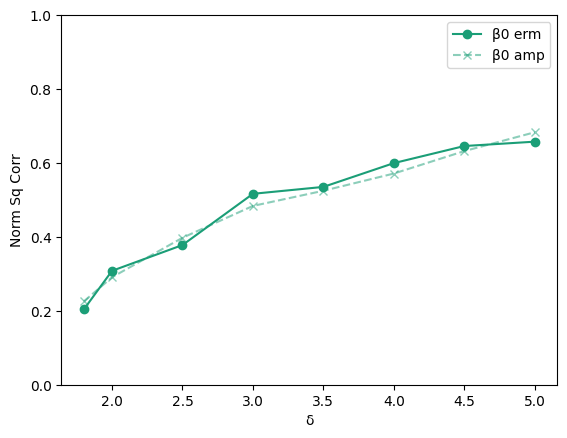

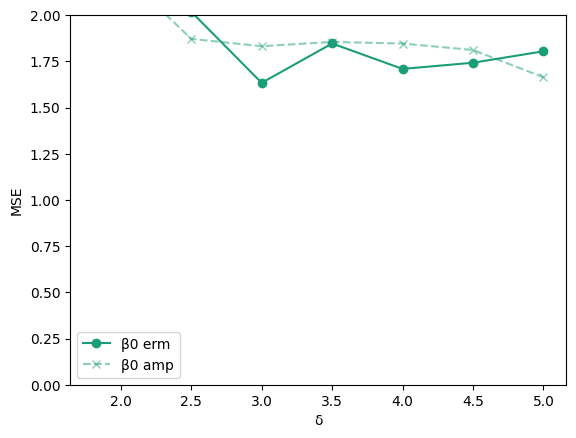

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 1000
L = 2 # num signals. L-1 changepoints

δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
noise_std = 0.5
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))

    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    # --- Run Weighted ERM and compare with the fixed point equations --- #
    B̂ = np.zeros((p, L))

    ℓ_ = 0
    # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
    print("σ̃ = ", σ̃)
    β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

    print("Regressing on signal ", ℓ_)
    sample_weight = (n - np.arange(n)) / n
    sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
    sk_lin_reg.fit(X, y, sample_weight = sample_weight)
    β̂ = sk_lin_reg.coef_

    B̂[:, ℓ_] = β̂
    erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
    amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

    comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
    comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
    erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
    amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
    G = np.random.randn(p)
    theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
ℓ_ = 0
plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
# plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()